In [17]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["LOKY_MAX_CPU_COUNT"] = "4"
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

In [18]:
df=pd.read_csv("EEG Eye State.csv")
print(df.shape)
df.head()

(14980, 15)


,AF3,F7,F3,FC5,T7,P7,O1,O2,P8,T8,FC6,F4,F8,AF4,eyeDetection
0,4329.23,4009.23,4289.23,4148.21,4350.26,4586.15,4096.92,4641.03,4222.05,4238.46,4211.28,4280.51,4635.90,4393.85,0
1,4324.62,4004.62,4293.85,4148.72,4342.05,4586.67,4097.44,4638.97,4210.77,4226.67,4207.69,4279.49,4632.82,4384.10,0
2,4327.69,4006.67,4295.38,4156.41,4336.92,4583.59,4096.92,4630.26,4207.69,4222.05,4206.67,4282.05,4628.72,4389.23,0
3,4328.72,4011.79,4296.41,4155.90,4343.59,4582.56,4097.44,4630.77,4217.44,4235.38,4210.77,4287.69,4632.31,4396.41,0
4,4326.15,4011.79,4292.31,4151.28,4347.69,4586.67,4095.90,4627.69,4210.77,4244.10,4212.82,4288.21,4632.82,4398.46,0


In [19]:
print(df.dtypes)

AF3             float64
F7              float64
F3              float64
FC5             float64
T7              float64
P7              float64
O1              float64
O2              float64
P8              float64
T8              float64
FC6             float64
F4              float64
F8              float64
AF4             float64
eyeDetection      int64
dtype: object


In [20]:
print(df.isnull().sum())

AF3             0
F7              0
F3              0
FC5             0
T7              0
P7              0
O1              0
O2              0
P8              0
T8              0
FC6             0
F4              0
F8              0
AF4             0
eyeDetection    0
dtype: int64


In [21]:
feature_cols= [c for c in df.columns if c!= 'eyeDetection']
print(features_cols)

['AF3', 'F7', 'F3', 'FC5', 'T7', 'P7', 'O1', 'O2', 'P8', 'T8', 'FC6', 'F4', 'F8', 'AF4']


In [22]:
z = (df[feature_cols] - df[feature_cols].mean()) / df[feature_cols].std()
mask_keep = (z.abs() <= 10).all(axis=1)

df_clean = df[mask_keep].reset_index(drop=True)
print("Rows removed as extreme outliers:", (~mask_keep).sum())
print("Shape after cleaning:", df_clean.shape)

Rows removed as extreme outliers: 4
Shape after cleaning: (14976, 15)


In [23]:
X_original = df_cleaned[feature_cols]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_original)
print("Scaled feature matrix shape:", X_scaled.shape)

Scaled feature matrix shape: (14976, 14)


In [24]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by the 2 PCA components:",
      pca.explained_variance_ratio_.round(3),
      "| total:", round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by the 2 PCA components: [0.593 0.152] | total: 0.745


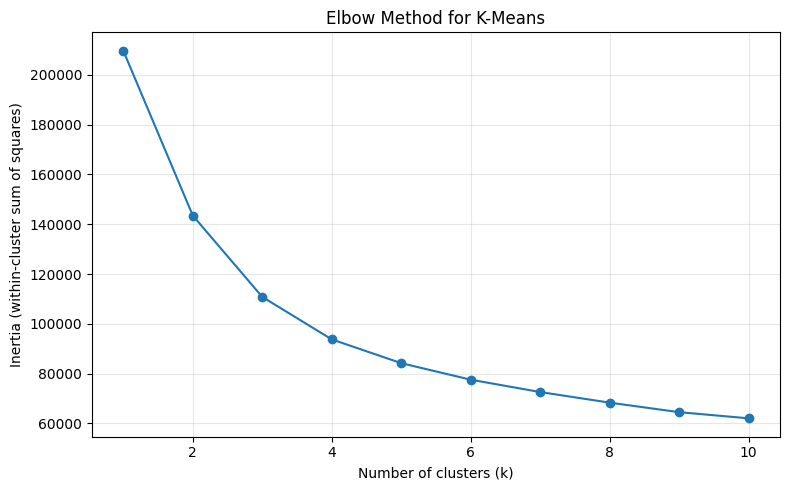

In [25]:
inertias = []
k_range = range(1, 11)
for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (within-cluster sum of squares)")
plt.title("Elbow Method for K-Means")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
print("Silhouette score by k:")
for k in range(2, 7):
    km = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    lab = km.fit_predict(X_scaled)
    print(f"  k={k}: silhouette = {silhouette_score(X_scaled, lab):.3f}")

Silhouette score by k:
  k=2: silhouette = 0.507
  k=3: silhouette = 0.280
  k=4: silhouette = 0.234
  k=5: silhouette = 0.189
  k=6: silhouette = 0.171


In [27]:
k = 2
kmeans = KMeans(n_clusters=k, init="random", n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("K-Means (init='random')")
print("  Inertia        :", round(kmeans.inertia_, 1))
print("  Iterations      :", kmeans.n_iter_)
print("  Silhouette score:", round(silhouette_score(X_scaled, kmeans_labels), 3))
print("  Cluster sizes   :", pd.Series(kmeans_labels).value_counts().sort_index().to_dict())

K-Means (init='random')
  Inertia        : 143470.3
  Iterations      : 11
  Silhouette score: 0.507
  Cluster sizes   : {0: 1795, 1: 13181}


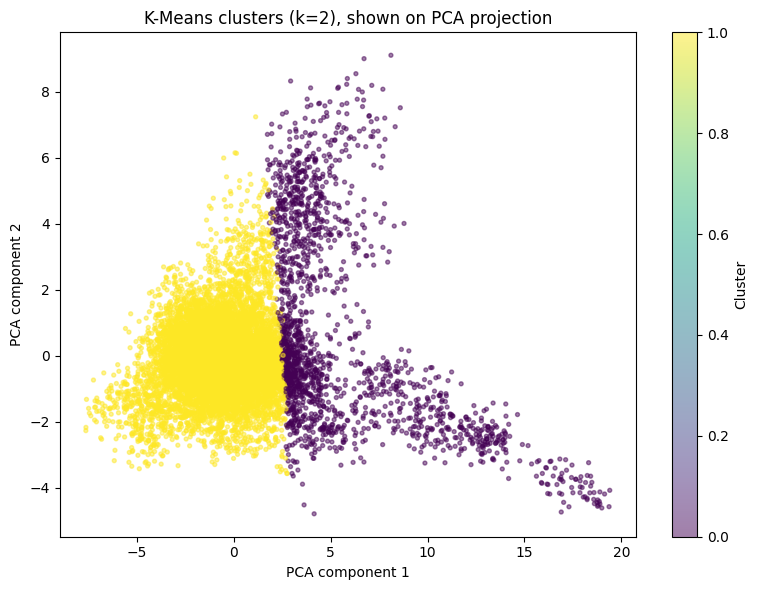

In [28]:
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap="viridis", s=8, alpha=0.5)
plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("K-Means clusters (k=2), shown on PCA projection")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

In [29]:
kmeanspp = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
kmeanspp_labels = kmeanspp.fit_predict(X_scaled)

print("K-Means++ (init='k-means++')")
print("  Inertia        :", round(kmeanspp.inertia_, 1))
print("  Iterations      :", kmeanspp.n_iter_)
print("  Silhouette score:", round(silhouette_score(X_scaled, kmeanspp_labels), 3))
print("  Cluster sizes   :", pd.Series(kmeanspp_labels).value_counts().sort_index().to_dict())

K-Means++ (init='k-means++')
  Inertia        : 143470.3
  Iterations      : 29
  Silhouette score: 0.507
  Cluster sizes   : {0: 13181, 1: 1795}
